# **Loading a video with OpenCV and spatial/temporal segmentation**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import os, cv2, math, base64, shutil, subprocess
from matplotlib.gridspec import GridSpec
from IPython.display import HTML, display
from sklearn.mixture import GaussianMixture



## **I. Video acquisition, loading and saving**

In [ ]:
VIDEO_PATH = "/content/drive/MyDrive/Analyse Video/Seq1.mp4"
OUT_DIR = "/content/drive/MyDrive/Analyse Video/Frames"              # folder where frames will be saved
os.makedirs(OUT_DIR, exist_ok=True)

In [ ]:
video = cv2.VideoCapture(VIDEO_PATH)
if not video.isOpened():
    raise SystemExit(f"Cannot open '{VIDEO_PATH}'. Check the file name / folder.")

In [ ]:
width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
n_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
fps = video.get(cv2.CAP_PROP_FPS)

print("----- Video information -----")
print(f"Width    : {width} px")
print(f"Height   : {height} px")
print(f"Frames   : {n_frames}")
print(f"FPS (Frame per second)      : {fps:.2f}")
print(f"Duration : {n_frames / fps:.2f} s   (frames / fps)")

----- Video information -----
Width    : 1920 px
Height   : 1080 px
Frames   : 174
FPS (Frame per second)      : 29.86
Duration : 5.83 s   (frames / fps)


In [ ]:
index = 0
while True:
    ok, frame = video.read()
    if not ok:                       # no more frames -> stop
        break
    # imwrite saves an image: the number in the name = frame index
    cv2.imwrite(os.path.join(OUT_DIR, f"frame_{index:04d}.png"), frame)
    index += 1
print(f"{index} frames saved in '{OUT_DIR}/'")

174 frames saved in '/content/drive/MyDrive/Analyse Video/Frames/'


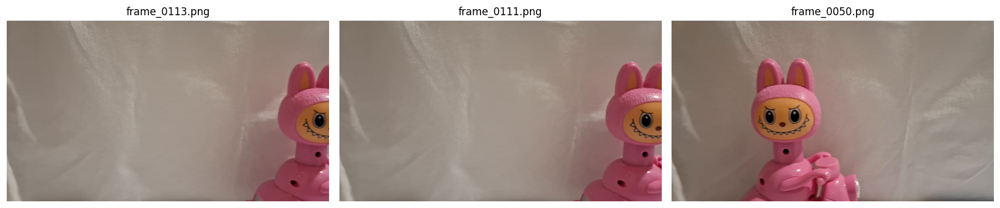

In [ ]:
# List the extracted color frames
files = sorted(
    f for f in os.listdir(OUT_DIR)
    if f.startswith("frame_") and f.endswith(".png")
)

# Select 3 random frames
selected = random.sample(files, min(3, len(files)))

# Display them
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, filename in zip(axes, selected):
    img = cv2.imread(os.path.join(OUT_DIR, filename))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
video.release()            # free the file
cv2.destroyAllWindows()    # close all the windows

## **II. Spatial segmentation**

I organized the project into separate folders for extracted frames, figures, and processed videos. This structure keeps the results organized and easy to access.

In [ ]:
BASE_DIR  = "/content/drive/MyDrive/Analyse Video"
FRAME_DIR = os.path.join(BASE_DIR, "Frames")
FIG_DIR   = os.path.join(BASE_DIR, "Figures")
VID_DIR   = os.path.join(BASE_DIR, "Videos")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(VID_DIR, exist_ok=True)

I loaded the extracted frames in chronological order and checked that each image was available. These checks help prevent missing or unreadable frames from affecting later processing.

In [ ]:
frame_files = sorted(
    f for f in os.listdir(FRAME_DIR)
    if f.startswith("frame_") and f.endswith(".png")
)

assert frame_files, f"No extracted frames found in {FRAME_DIR}"

frames = [
    cv2.imread(os.path.join(FRAME_DIR, filename))
    for filename in frame_files
]

assert all(frame is not None for frame in frames), \
    "Some frames could not be loaded correctly."

I resized the frames to a maximum width of 640 pixels to reduce processing costs while preserving their aspect ratio.


| | Original video | Resized video |
|---|---|---|
| **Dimensions** | 1920 × 1080 | 640 × 360 |
| **Pixels per frame** | 2,073,600 | 230,400 |


The resized frames contain about 89% fewer pixels. This reduces the amount of data that image-processing algorithms must handle.

In [ ]:
SCALE_W = 640            # processing width (None = keep original size)

# downscale + even dimensions (H.264 needs even width/height)
if SCALE_W and frames[0].shape[1] > SCALE_W:
    frames = [cv2.resize(f, (SCALE_W, int(f.shape[0] * SCALE_W / f.shape[1])),
                         interpolation=cv2.INTER_AREA) for f in frames]
frames = [f[: f.shape[0] // 2 * 2, : f.shape[1] // 2 * 2] for f in frames]

_cap = cv2.VideoCapture(VIDEO_PATH)
fps = _cap.get(cv2.CAP_PROP_FPS) or 25.0
_cap.release()

N_FR = len(frames)
H, W = frames[0].shape[:2]
SAMPLE_IDX = [int(x * N_FR) for x in (0.2, 0.4, 0.6, 0.8)]   # 4 frames shown in the figures
time_axis = np.arange(N_FR) / fps
print(f"{N_FR} frames | {W}x{H} | {fps:.2f} fps")

174 frames | 640x360 | 29.86 fps


I configured a consistent plotting style to make the generated figures clearer and easier to compare.

In [ ]:
# ---------- plot style ----------
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10, "legend.frameon": False})
PALETTE = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#17becf"]

I defined reusable functions to display images, save figures, generate videos, compare processing results, and measure foreground ratios. These functions simplify the implementation and evaluation of the segmentation methods.



In [ ]:
# ---------- helpers (shared by all parts) ----------
def to_rgb(img):
    """BGR -> RGB for matplotlib (gray images are returned unchanged)."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

def write_video(name, frame_list):
    """Write a video in Videos/ and re-encode it in H.264 so it plays in the notebook."""
    path = os.path.join(VID_DIR, name)
    tmp = path.replace(".mp4", "_raw.mp4")
    h, w = frame_list[0].shape[:2]
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h), frame_list[0].ndim == 3)
    for fr in frame_list:
        vw.write(fr)
    vw.release()
    try:
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", tmp, "-vcodec", "libx264",
                        "-pix_fmt", "yuv420p", path], check=True)
        os.remove(tmp)
    except Exception:
        os.replace(tmp, path)
    return path

def show_video(path, width=800):
    """Display a video inside the notebook."""
    data = base64.b64encode(open(path, "rb").read()).decode()
    display(HTML(f'<video width="{width}" controls loop>'
                 f'<source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

def label(img, text):
    """Burn a title bar on an image (used for the side-by-side videos)."""
    out = img.copy() if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    cv2.rectangle(out, (0, 0), (out.shape[1], 26), (0, 0, 0), -1)
    cv2.putText(out, text, (8, 19), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    return out

def side_by_side(lists, titles):
    """Concatenate several frame lists horizontally -> one list of frames."""
    return [np.hstack([label(l[i], t) for l, t in zip(lists, titles)]) for i in range(len(lists[0]))]

def image_grid(imgs, row_labels, col_labels, title, fname, cell=3.2):
    """Grid of images (rows x columns) with labels, saved in Figures/."""
    R, C = len(imgs), len(imgs[0])
    fig, axes = plt.subplots(R, C, figsize=(cell * C + 1.2, cell * R * 0.75 + 0.9), squeeze=False)
    for r in range(R):
        for c in range(C):
            ax = axes[r][c]
            ax.imshow(to_rgb(imgs[r][c]), cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(False)
            if r == 0: ax.set_title(col_labels[c])
            if c == 0: ax.set_ylabel(row_labels[r], fontsize=10)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout(); save_fig(fname); plt.show()

def fg_ratio(masks):
    """Percentage of white (foreground) pixels of each binary mask."""
    return [100 * np.count_nonzero(m) / m.size for m in masks]


 **`fg_ratio(masks)`**

Calculates the percentage of white pixels in each binary mask:

$$
\text{Foreground ratio} = \frac{\text{Number of white pixels}}{\text{Total pixels}} \times 100
$$

This measurement will help quantify how much of each frame a segmentation method classifies as foreground.

Converted the colored frames we have to grayscale.

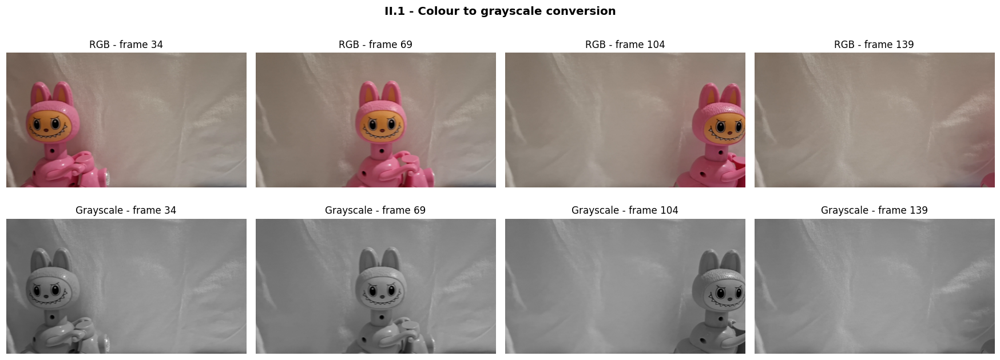

In [ ]:
gray = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]
write_video("gray.mp4", gray)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.2))
for c, idx in enumerate(SAMPLE_IDX):
    axes[0, c].imshow(to_rgb(frames[idx])); axes[0, c].set_title(f"RGB - frame {idx}")
    axes[1, c].imshow(gray[idx], cmap="gray", vmin=0, vmax=255); axes[1, c].set_title(f"Grayscale - frame {idx}")
    for r in range(2):
        axes[r, c].axis("off")
fig.suptitle("II.1 - Colour to grayscale conversion", fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("II1_gray_conversion.png")
plt.show()

### **Heuristic global thresholding :**

I selected the middle frame to test global thresholding. I used six initial thresholds to study their influence on convergence and set a tolerance of 0.5 with a maximum of 200 iterations.


- The loop logic:

  1. choose T0
  2. G1 = pixels > T, G2 = pixels <= T
  with :
  
    * G1: pixels brighter than the current threshold.

    * G2: pixels darker than or equal to the current threshold.

  3. means m1, m2 (from the histogram)   
  4. T = (m1+m2)/2   
  5. repeat until stable

In [ ]:
FOI_II    = N_FR // 2                      # frame of interest used in part II
T0_LIST   = [10, 50, 100, 128, 180, 240]   # different initial thresholds to test
EPS       = 0.5                            # stop when |T_new - T| < EPS
MAX_ITER  = 200

def heuristic_threshold(img, T0, eps=EPS, max_iter=MAX_ITER):
    hist = np.bincount(img.ravel(), minlength=256).astype(float)
    lv = np.arange(256)
    T = float(T0); history = [T]
    for _ in range(max_iter):
        g1, g2 = lv > T, lv <= T
        if hist[g1].sum() == 0 or hist[g2].sum() == 0:      # degenerate T0: one group empty
            T = float(img.mean()); history.append(T); continue
        m1 = (lv[g1] * hist[g1]).sum() / hist[g1].sum()
        m2 = (lv[g2] * hist[g2]).sum() / hist[g2].sum()
        T_new = (m1 + m2) / 2; history.append(T_new)
        if abs(T_new - T) < eps:
            T = T_new; break
        T = T_new
    return T, history

img = gray[FOI_II]
results = {T0: heuristic_threshold(img, T0) for T0 in T0_LIST}
t_otsu, _ = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"{'T0':>5} | {'T_final':>8} | iterations")
for T0, (Tf, hist_T) in results.items():
    print(f"{T0:>5} | {Tf:8.2f} | {len(hist_T) - 1}")
print(f"Otsu threshold (for comparison): {t_otsu:.0f}")


   T0 |  T_final | iterations
   10 |   110.96 | 7
   50 |   110.96 | 7
  100 |   110.96 | 4
  128 |   117.16 | 8
  180 |   117.16 | 14
  240 |   117.16 | 16
Otsu threshold (for comparison): 111


I tested six initial thresholds on the same grayscale frame and recorded their final values and iteration counts. I also calculated Otsu's threshold as a reference for comparing the two methods.

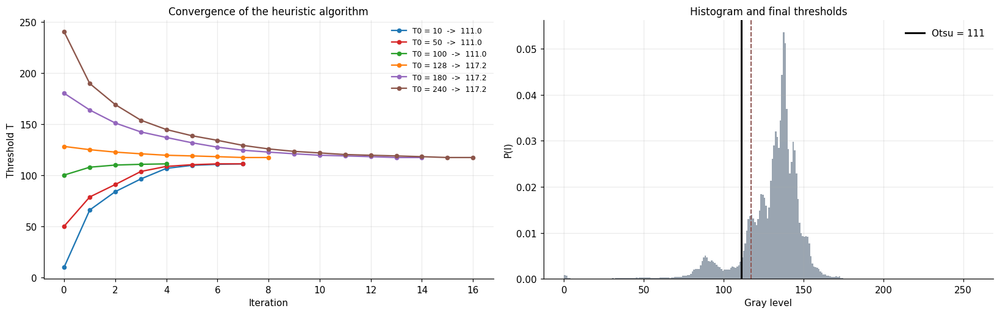

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for (T0, (Tf, hist_T)), col in zip(results.items(), PALETTE):
    ax[0].plot(hist_T, "-o", ms=4, color=col, label=f"T0 = {T0}  ->  {Tf:.1f}")
ax[0].set(xlabel="Iteration", ylabel="Threshold T", title="Convergence of the heuristic algorithm")
ax[0].legend(fontsize=8)
ax[1].hist(img.ravel(), bins=256, range=(0, 256), color="#9aa5b1", density=True)
for (T0, (Tf, _)), col in zip(results.items(), PALETTE):
    ax[1].axvline(Tf, color=col, ls="--", lw=1.2)
ax[1].axvline(t_otsu, color="k", lw=2, label=f"Otsu = {t_otsu:.0f}")
ax[1].set(xlabel="Gray level", ylabel="P(I)", title="Histogram and final thresholds")
ax[1].legend()
plt.tight_layout()
save_fig("II2_heuristic_convergence.png")
plt.show()

The convergence plot shows how the heuristic algorithm updates the threshold from different initial values. The histogram compares the final heuristic thresholds with Otsu's threshold and shows how they divide the grayscale intensities.

The model provides three parameters for each Gaussian:

| Parameter | Description |
|---|---|
| `mu` | Mean intensity |
| `var` | Intensity variance |
| `P` | Mixture weight, representing the proportion assigned to that component |

The code applies Equation (5):

$$
T = \frac{\mu_1 + \mu_2}{2}
+ \frac{\sigma^2}{\mu_1 - \mu_2}
\ln\left(\frac{P(k_1)}{P(k_2)}\right)
$$




The mixture curve Combines both Gaussian components to approximate the observed histogram.



$$
p(I) = P(k_1)\,G_1(I) + P(k_2)\,G_2(I)
$$

where:

| Symbol | Meaning |
|---|---|
| $p(I)$ | Combined (mixture) probability density at intensity $I$ |
| $G_1(I), G_2(I)$ | Individual Gaussian distributions of components $k_1$ and $k_2$ |
| $P(k_1), P(k_2)$ | Mixture weights (proportions) assigned to each component |

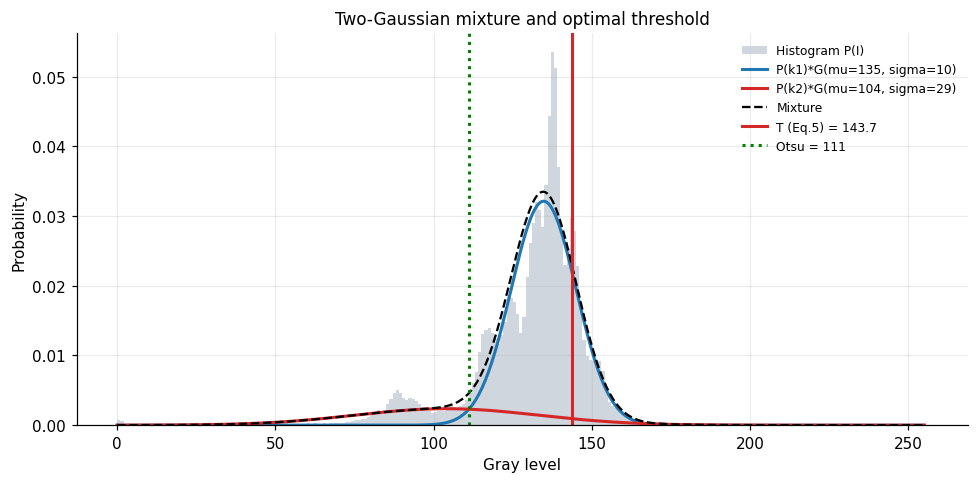

In [ ]:
# 2-Gaussian mixture + threshold of Eq.(5)
GMM_SUBSAMPLE = 5                          # use 1 pixel out of 5 to fit the GMM (speed)

gmm = GaussianMixture(2, random_state=0).fit(img.reshape(-1, 1)[::GMM_SUBSAMPLE].astype(float))
mu, var, P = gmm.means_.ravel(), gmm.covariances_.ravel(), gmm.weights_
T_gmm = mu.mean() + var.mean() / (mu[0] - mu[1]) * np.log(P[0] / P[1])

x = np.linspace(0, 255, 512)
gauss = lambda x, m, v: np.exp(-(x - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(img.ravel(), bins=256, range=(0, 256), density=True, color="#cfd6dd", label="Histogram P(I)")
for k, col in zip(range(2), PALETTE):
    ax.plot(x, P[k] * gauss(x, mu[k], var[k]), color=col, lw=2,
            label=f"P(k{k+1})*G(mu={mu[k]:.0f}, sigma={np.sqrt(var[k]):.0f})")
ax.plot(x, sum(P[k] * gauss(x, mu[k], var[k]) for k in range(2)), "k--", lw=1.5, label="Mixture")
ax.axvline(T_gmm, color="#d62728", lw=2, label=f"T (Eq.5) = {T_gmm:.1f}")
ax.axvline(t_otsu, color="green", lw=2, ls=":", label=f"Otsu = {t_otsu:.0f}")
ax.set(xlabel="Gray level", ylabel="Probability", title="Two-Gaussian mixture and optimal threshold")
ax.legend(fontsize=8)
plt.tight_layout(); save_fig("II2b_gaussian_mixture.png")
plt.show()


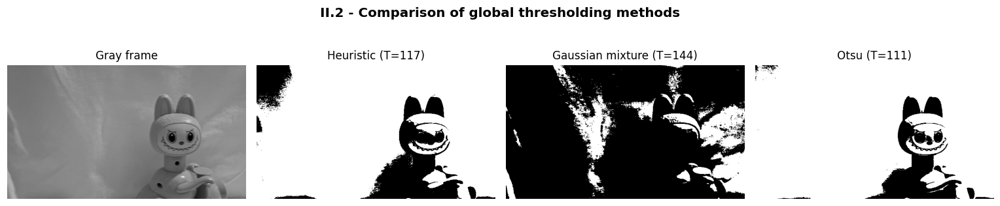

In [ ]:
# --- visual comparison of the thresholds ------------------------------------
T_heur = results[128][0]
seg = [img, ((img > T_heur) * 255).astype(np.uint8),
       ((img > T_gmm) * 255).astype(np.uint8), ((img > t_otsu) * 255).astype(np.uint8)]
image_grid([seg], [""],
           ["Gray frame", f"Heuristic (T={T_heur:.0f})", f"Gaussian mixture (T={T_gmm:.0f})", f"Otsu (T={t_otsu:.0f})"],
           "II.2 - Comparison of global thresholding methods", "II2_threshold_comparison.png")

## **Otsu segmentation of the whole video:**

I implemented Otsu's method by calculating the grayscale intensity histogram and evaluating the between-class variance for all possible thresholds. The algorithm selects the threshold that maximizes this variance, providing an automatic way to separate each frame into two intensity classes.

In [ ]:
VIDEO_WIDTH_II3 = 900                      # display width of the notebook video

def otsu_curve(im):
    """Own Otsu implementation: returns sigma_B^2(T) for T = 0..255 and its argmax."""
    p = np.bincount(im.ravel(), minlength=256) / im.size
    i = np.arange(256)
    P1 = np.cumsum(p); m = np.cumsum(i * p); mG = m[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        sB = (mG * P1 - m) ** 2 / (P1 * (1 - P1))
    sB = np.nan_to_num(sB)
    return sB, int(np.argmax(sB))


Own Otsu implementation: T = 111 | OpenCV: T = 111


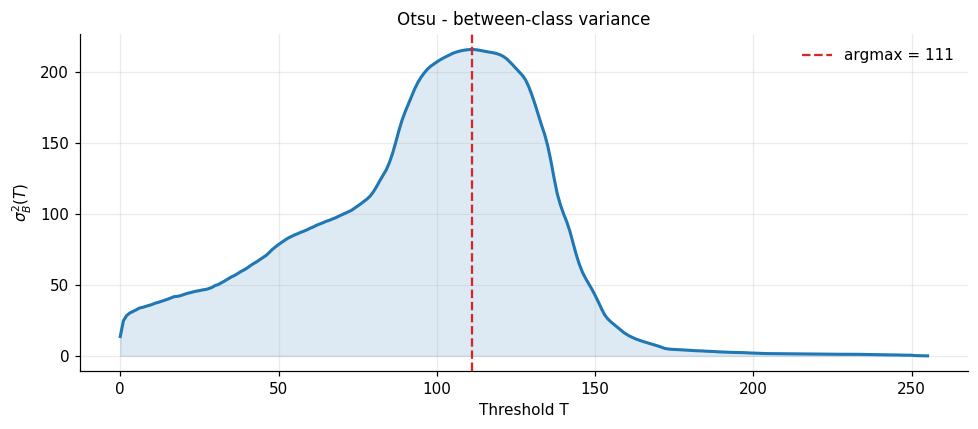

In [ ]:
sB, t_mine = otsu_curve(img)
print(f"Own Otsu implementation: T = {t_mine} | OpenCV: T = {t_otsu:.0f}")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sB, color=PALETTE[0], lw=2)
ax.fill_between(np.arange(256), sB, alpha=0.15, color=PALETTE[0])
ax.axvline(t_mine, color=PALETTE[1], ls="--", label=f"argmax = {t_mine}")
ax.set(xlabel="Threshold T", ylabel=r"$\sigma_B^2(T)$", title="Otsu - between-class variance")
ax.legend()
plt.tight_layout()
save_fig("II3_otsu_curve.png")
plt.show()



I plotted the between-class variance across all possible thresholds. The optimal threshold corresponds to the maximum of this curve. I also compared my implementation with OpenCV to verify that both methods select the same or a similar threshold.

In [ ]:
otsu_masks, otsu_T = [], []
for g in gray:
    t, m = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    otsu_masks.append(m)
    otsu_T.append(t)

# original video | segmented video (one window = both side by side)
p = write_video("otsu_side_by_side.mp4", side_by_side([frames, otsu_masks], ["Original", "Otsu segmentation"]))
show_video(p, VIDEO_WIDTH_II3)


I applied Otsu's method independently to every grayscale frame. This produced a binary video and a threshold value for each frame.

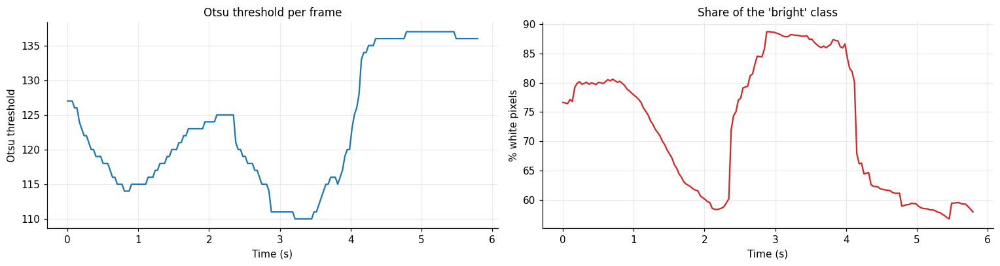

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(time_axis, otsu_T, color=PALETTE[0])
ax[0].set(xlabel="Time (s)", ylabel="Otsu threshold", title="Otsu threshold per frame")
ax[1].plot(time_axis, fg_ratio(otsu_masks), color=PALETTE[1])
ax[1].set(xlabel="Time (s)", ylabel="% white pixels", title="Share of the 'bright' class")
plt.tight_layout(); save_fig("II3_otsu_over_time.png")
plt.show()

I plotted the Otsu threshold and the percentage of white pixels over time. These plots show how the intensity distribution and the size of the bright class change throughout the video. However, white regions may include both the moving object and the background.

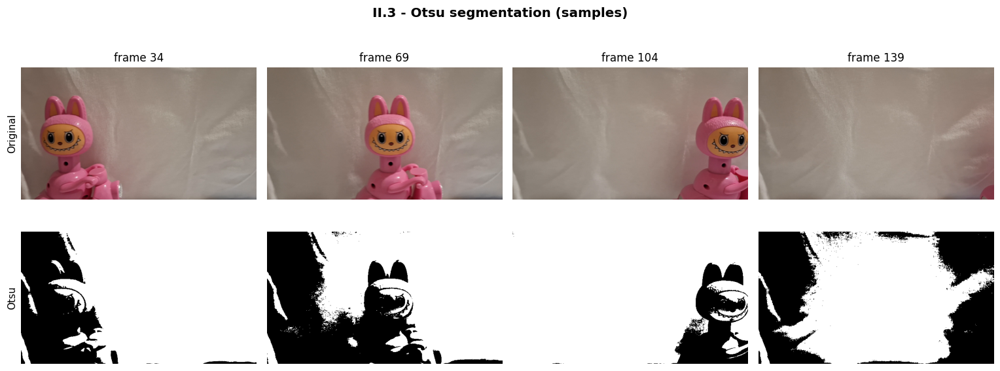

In [ ]:
image_grid([[frames[i] for i in SAMPLE_IDX], [otsu_masks[i] for i in SAMPLE_IDX]], ["Original", "Otsu"],
           [f"frame {i}" for i in SAMPLE_IDX], "II.3 - Otsu segmentation (samples)", "II3_otsu_samples.png")

## **III. Temporal Segmentation:**

I converted all frames to grayscale and applied Gaussian blur to reduce noise before motion detection. I also defined a post-processing function to remove isolated pixels and fill small holes in the resulting masks.

In [ ]:
# Shared pre-processing of part III (grayscale + optional light blur against noise)
USE_BLUR = True                            # Gaussian blur before temporal differencing
BLUR_K   = 5                               # kernel size (odd)
POST_K   = 5                               # kernel size of the post-processing filters

gs = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]
if USE_BLUR:
    gs = [cv2.GaussianBlur(g, (BLUR_K, BLUR_K), 0) for g in gs]

def postprocess(mask, k=POST_K):
    """Post-processing: median filter, then opening (false positives) and closing (holes)."""
    m = cv2.medianBlur(mask, k)
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    return cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, ker), cv2.MORPH_CLOSE, ker)


I detected motion by calculating the absolute difference between consecutive grayscale frames. Pixels with differences above 25 appear white in the output mask. This method highlights changes between frames, but it can also detect noise and may show only parts of a moving object.

In [ ]:
# III.1  Subtraction of image t-1 :  D = 255 if |I(t) - I(t-1)| > lambda
LAMBDA_T1 = 25                             # detection threshold

def diff_t1(gs, lam):
    """B(t) = I(t-1): the previous frame is the background model."""
    return [np.zeros_like(gs[0])] + [((cv2.absdiff(gs[t], gs[t - 1]) > lam) * 255).astype(np.uint8)
                                     for t in range(1, len(gs))]

m_t1 = diff_t1(gs, LAMBDA_T1)
p = write_video("diff_t1.mp4", side_by_side([frames, m_t1], ["Original", "|I(t) - I(t-1)| > lambda"]))
show_video(p, 900)


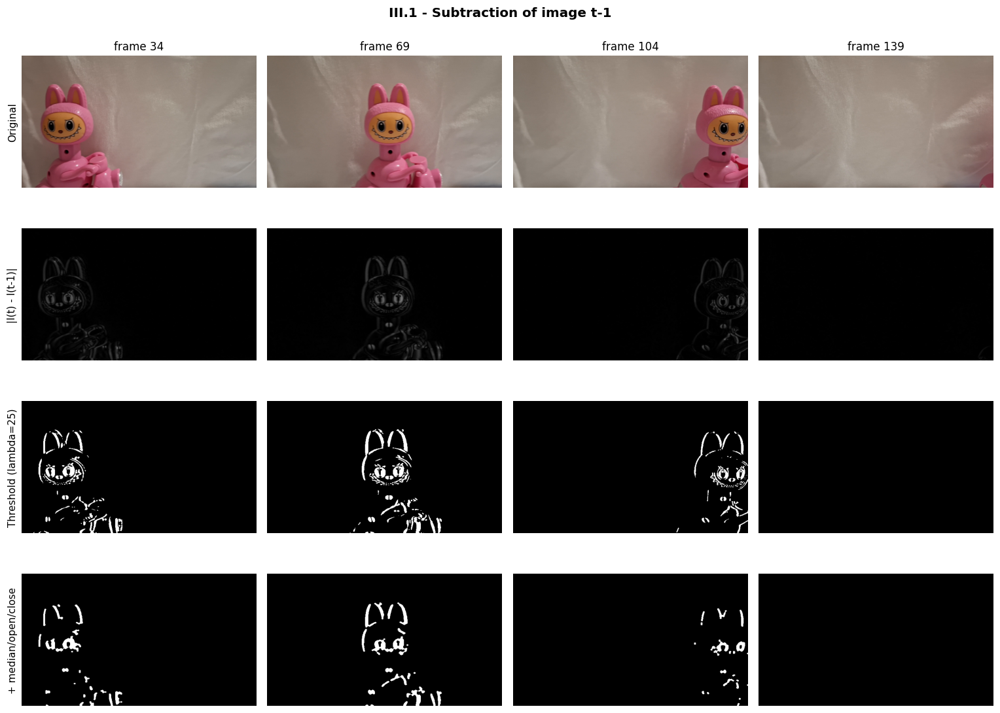

In [ ]:
image_grid([[frames[i] for i in SAMPLE_IDX],
            [cv2.absdiff(gs[i], gs[i - 1]) for i in SAMPLE_IDX],
            [m_t1[i] for i in SAMPLE_IDX],
            [postprocess(m_t1[i]) for i in SAMPLE_IDX]],
           ["Original", "|I(t) - I(t-1)|", f"Threshold (lambda={LAMBDA_T1})", "+ median/open/close"],
           [f"frame {i}" for i in SAMPLE_IDX], "III.1 - Subtraction of image t-1", "III1_diff_t1.png")

The comparison shows how frame differencing detects motion by highlighting pixel changes between consecutive frames. Thresholding removes small intensity variations, while post-processing reduces noise and improves the continuity of detected regions.

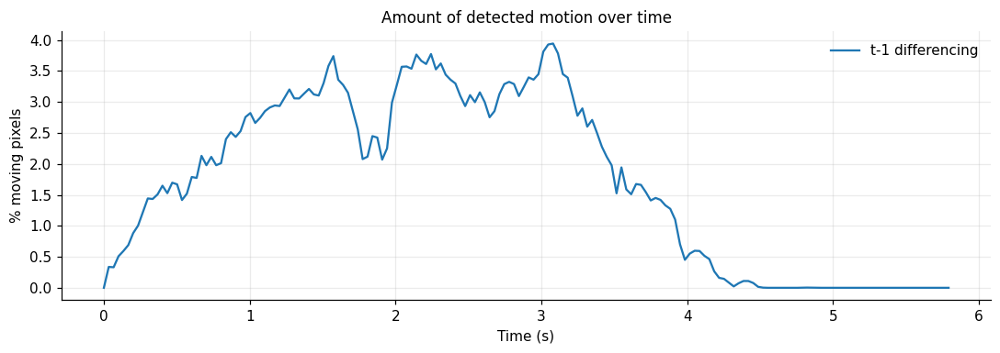

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(time_axis, fg_ratio(m_t1), color=PALETTE[0], label="t-1 differencing")
ax.set(xlabel="Time (s)", ylabel="% moving pixels", title="Amount of detected motion over time"); ax.legend()
plt.tight_layout(); save_fig("III1_motion_over_time.png")
plt.show()

The plot shows how the amount of detected motion changes throughout the video. Peaks indicate frames with more pixel changes, while lower values indicate less detected motion.

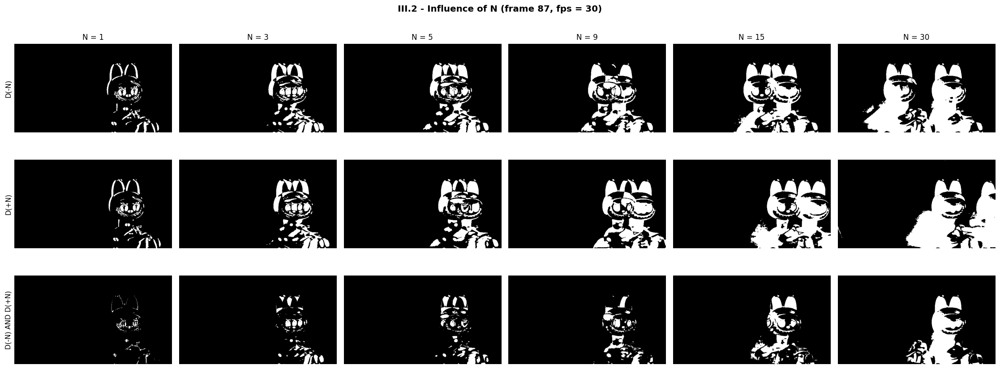

In [ ]:
LAMBDA_3F  = 25                            # detection threshold
FOI_3F     = N_FR // 2                     # frame used for the N comparison
N_CANDIDATES = [1, 3, 5, 9, 15, int(round(fps / 2)), int(round(fps))]   # values of N to compare
N_CHOSEN   = 5                             # <- set after looking at the figure

def three_frame(gs, N, lam):
    out = [np.zeros_like(gs[0]) for _ in gs]
    for t in range(N, len(gs) - N):
        dm = cv2.absdiff(gs[t], gs[t - N]) > lam       # where the object was + where it is
        dp = cv2.absdiff(gs[t + N], gs[t]) > lam       # where the object is + where it will be
        out[t] = ((dm & dp) * 255).astype(np.uint8)    # AND -> where the object is now
    return out

maxN = min(FOI_3F, N_FR - 1 - FOI_3F)
N_list = sorted({n for n in N_CANDIDATES if 1 <= n <= maxN})[:6]
rows = [[], [], []]; areas = []
for N in N_list:
    dm = ((cv2.absdiff(gs[FOI_3F], gs[FOI_3F - N]) > LAMBDA_3F) * 255).astype(np.uint8)
    dp = ((cv2.absdiff(gs[FOI_3F + N], gs[FOI_3F]) > LAMBDA_3F) * 255).astype(np.uint8)
    both = cv2.bitwise_and(dm, dp)
    rows[0].append(dm); rows[1].append(dp); rows[2].append(both)
    areas.append(100 * np.count_nonzero(both) / both.size)
image_grid(rows, ["D(-N)", "D(+N)", "D(-N) AND D(+N)"], [f"N = {n}" for n in N_list],
           f"III.2 - Influence of N (frame {FOI_3F}, fps = {fps:.0f})", "III2_choice_of_N.png")


Three-frame differencing combines motion information from frames before and after the current frame. The logical AND operation keeps pixels that change in both comparisons, helping isolate motion around the current frame.

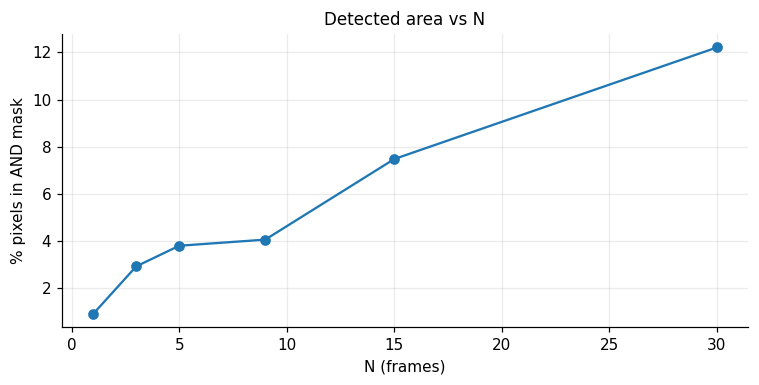

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(N_list, areas, "-o", color=PALETTE[0])
ax.set(xlabel="N (frames)", ylabel="% pixels in AND mask", title="Detected area vs N")
plt.tight_layout(); save_fig("III2_area_vs_N.png")
plt.show()

In [ ]:
m_3f = three_frame(gs, N_CHOSEN, LAMBDA_3F)
p = write_video("three_frame.mp4", side_by_side([frames, m_3f], ["Original", f"3-frame differencing (N={N_CHOSEN})"]))
show_video(p, 900)


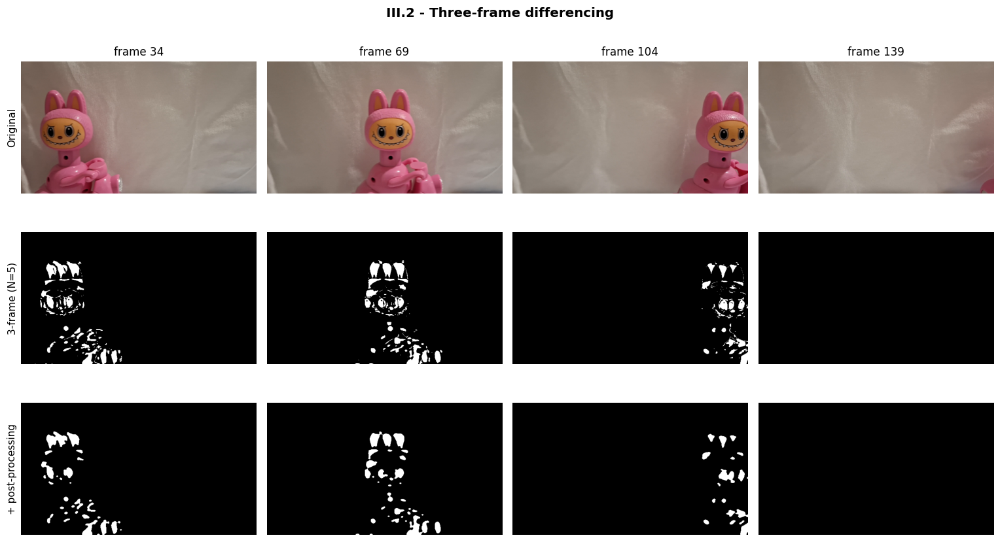

In [ ]:
image_grid([[frames[i] for i in SAMPLE_IDX], [m_3f[i] for i in SAMPLE_IDX], [postprocess(m_3f[i]) for i in SAMPLE_IDX]],
           ["Original", f"3-frame (N={N_CHOSEN})", "+ post-processing"], [f"frame {i}" for i in SAMPLE_IDX],
           "III.2 - Three-frame differencing", "III2_three_frame.png")

## **Adaptive background subtraction**

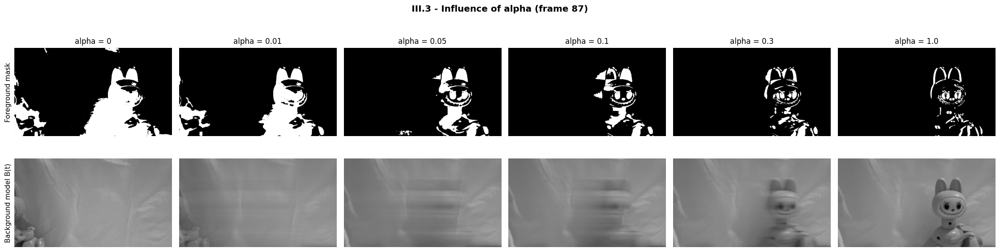

In [ ]:
LAMBDA_AD    = 25                          # detection threshold
FOI_AD       = N_FR // 2                   # frame used for the alpha comparison
ALPHAS       = [0, 0.01, 0.05, 0.1, 0.3, 1.0]   # values of alpha to compare
ALPHA_CHOSEN = 0.05

def adaptive_bg(gs, alpha, lam):
    B = gs[0].astype(np.float32)
    masks = [np.zeros_like(gs[0])]; bgs = [gs[0].copy()]
    for t in range(1, len(gs)):
        I = gs[t].astype(np.float32)
        masks.append(((np.abs(I - B) > lam) * 255).astype(np.uint8))
        B = alpha * I + (1 - alpha) * B                 # background update
        bgs.append(B.astype(np.uint8))
    return masks, bgs

res_a = {a: adaptive_bg(gs, a, LAMBDA_AD) for a in ALPHAS}
image_grid([[res_a[a][0][FOI_AD] for a in ALPHAS], [res_a[a][1][FOI_AD] for a in ALPHAS]],
           ["Foreground mask", "Background model B(t)"], [f"alpha = {a}" for a in ALPHAS],
           f"III.3 - Influence of alpha (frame {FOI_AD})", "III3_choice_of_alpha.png")


I implemented adaptive background subtraction by comparing each grayscale frame with an evolving background model. The parameter **alpha** controls how quickly the model adapts to changes in the scene. A small value preserves the background longer, while a large value adapts faster but may absorb moving objects. I compare several values of **alpha** to select a suitable balance between motion detection and background adaptation.

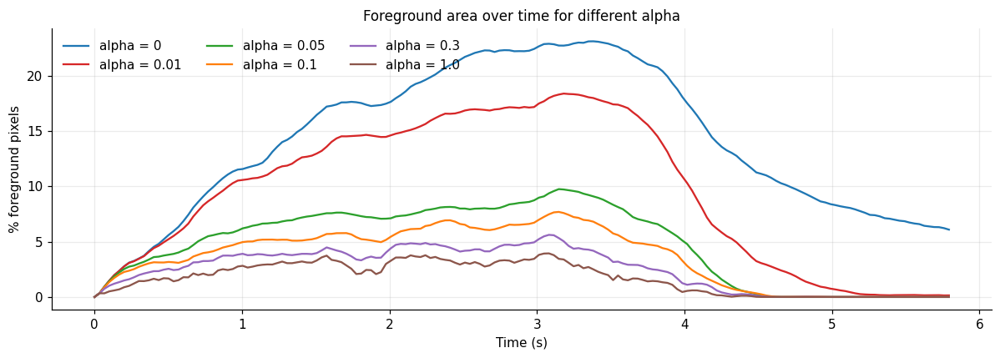

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
for a, col in zip(ALPHAS, PALETTE):
    ax.plot(time_axis, fg_ratio(res_a[a][0]), color=col, label=f"alpha = {a}")
ax.set(xlabel="Time (s)", ylabel="% foreground pixels", title="Foreground area over time for different alpha")
ax.legend(ncol=3)
plt.tight_layout(); save_fig("III3_alpha_curves.png")
plt.show()


In [ ]:
m_ad, bg_ad = adaptive_bg(gs, ALPHA_CHOSEN, LAMBDA_AD)
p = write_video("adaptive_bg.mp4", side_by_side([frames, bg_ad, m_ad],
                ["Original", f"Background (alpha={ALPHA_CHOSEN})", "Foreground"]))
show_video(p, 1000)

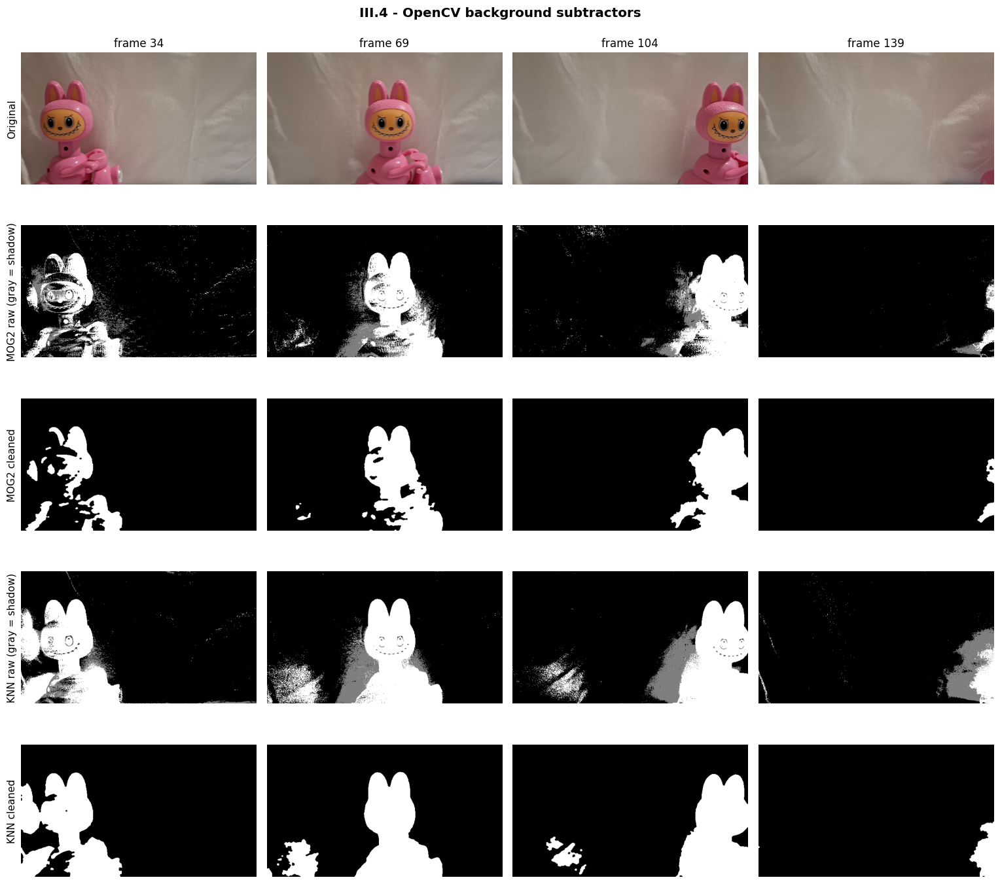

In [ ]:
# -----------------------------------------------------------------------------
#   MOG2 : each pixel is modelled by a mixture of K Gaussians (K adapted per pixel) whose
#          weights/means/variances are updated online, a pixel is background if it matches a
#          high-weight component, otherwise foreground. Copes with multimodal backgrounds
#          and flags shadows.
#   KNN  : non-parametric; each pixel keeps a history of its recent values and is background
#          if at least k samples lie within a distance threshold (K-nearest-neighbour density).
# -----------------------------------------------------------------------------
MOG2_HISTORY, MOG2_VAR_THRESH = 200, 16    # MOG2 parameters
KNN_HISTORY,  KNN_DIST2_THRESH = 200, 400.0  # KNN parameters
DETECT_SHADOWS = True                      # shadows are marked 127 (removed below)

def run_subtractor(sub, frames):
    raw, clean = [], []
    for f in frames:
        m = sub.apply(f); raw.append(m)
        clean.append(postprocess(((m == 255) * 255).astype(np.uint8)))   # drop shadows + denoise
    return raw, clean

mog_raw, m_mog = run_subtractor(
    cv2.createBackgroundSubtractorMOG2(history=MOG2_HISTORY, varThreshold=MOG2_VAR_THRESH,
                                       detectShadows=DETECT_SHADOWS), frames)
knn_raw, m_knn = run_subtractor(
    cv2.createBackgroundSubtractorKNN(history=KNN_HISTORY, dist2Threshold=KNN_DIST2_THRESH,
                                      detectShadows=DETECT_SHADOWS), frames)

image_grid([[frames[i] for i in SAMPLE_IDX], [mog_raw[i] for i in SAMPLE_IDX], [m_mog[i] for i in SAMPLE_IDX],
            [knn_raw[i] for i in SAMPLE_IDX], [m_knn[i] for i in SAMPLE_IDX]],
           ["Original", "MOG2 raw (gray = shadow)", "MOG2 cleaned", "KNN raw (gray = shadow)", "KNN cleaned"],
           [f"frame {i}" for i in SAMPLE_IDX], "III.4 - OpenCV background subtractors", "III4_mog2_knn.png")


In [ ]:
p = write_video("mog2_knn.mp4", side_by_side([frames, m_mog, m_knn], ["Original", "MOG2", "KNN"]))
show_video(p, 1000)

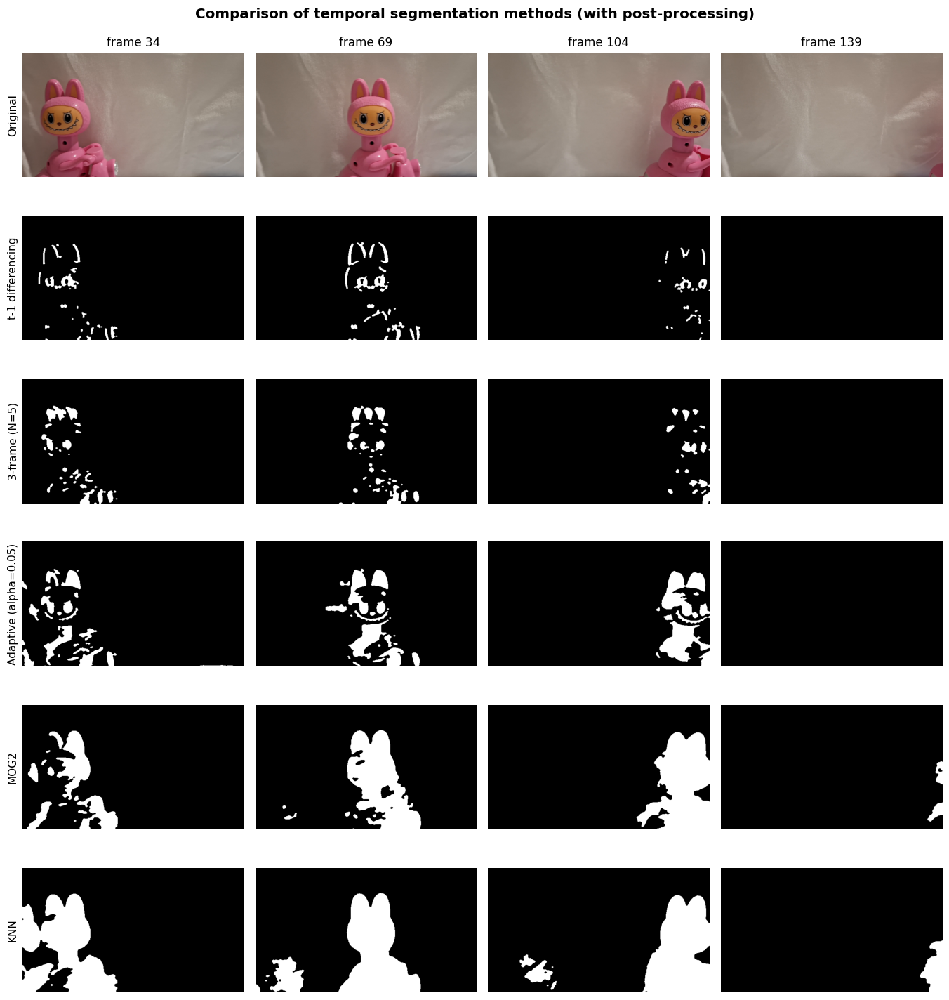

In [ ]:
# -----------------------------------------------------------------------------
# Final comparison of all temporal methods (needs III.1 to III.4 to have been run)
# -----------------------------------------------------------------------------
methods = {"t-1 differencing": m_t1, f"3-frame (N={N_CHOSEN})": m_3f,
           f"Adaptive (alpha={ALPHA_CHOSEN})": m_ad, "MOG2": m_mog, "KNN": m_knn}
image_grid([[frames[i] for i in SAMPLE_IDX]] + [[postprocess(m[i]) for i in SAMPLE_IDX] for m in methods.values()],
           ["Original"] + list(methods.keys()), [f"frame {i}" for i in SAMPLE_IDX],
           "Comparison of temporal segmentation methods (with post-processing)",
           "III_final_comparison.png", cell=2.8)


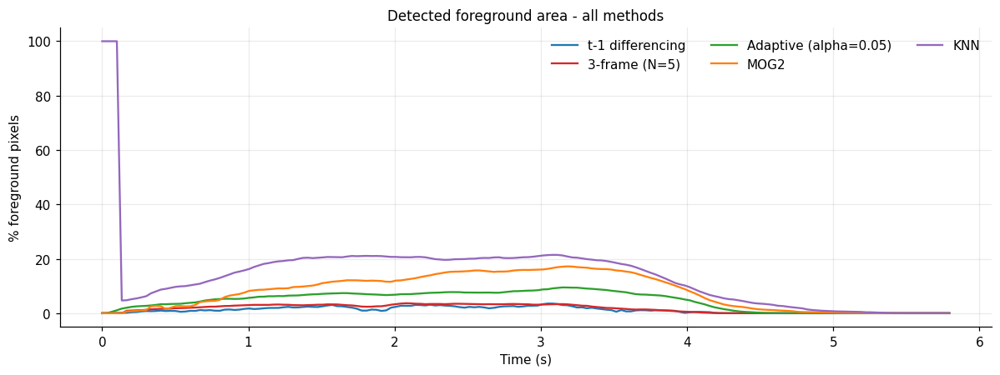

Figures -> /content/drive/MyDrive/Analyse Video/Figures | Videos -> /content/drive/MyDrive/Analyse Video/Videos


In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for (name, ms), col in zip(methods.items(), PALETTE):
    ax.plot(time_axis, fg_ratio([postprocess(m) for m in ms]), color=col, label=name)
ax.set(xlabel="Time (s)", ylabel="% foreground pixels", title="Detected foreground area - all methods")
ax.legend(ncol=3)
plt.tight_layout(); save_fig("III_final_curves.png"); plt.show()
print("Figures ->", FIG_DIR, "| Videos ->", VID_DIR)